<a href="https://colab.research.google.com/github/sancarg/Machine_Learning/blob/master/fraud_detection_xgb_with_deepcheck.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WELLCOME

Welcome to "***Fraud Detection Project***".

One of the challenges in this project is the absence of domain knowledge. So without knowing what the column names are, you will only be interested in their values. The other one is the class frequencies of the target variable are quite imbalanced.

You will implement ***Logistic Regression, Random Forest, XGBoost,and Neural Network*** algorithms and ***Unbalanced Data Techniques*** . Also visualize performances of the models using ***Seaborn, Matplotlib*** and ***Yellowbrick*** in a variety of ways.

Data drift and model drirft are key consepts about ML and MLOPS, you can monitor and check your data and models with plenty of ways and tools. ***Deepchecks*** is one of them and the leading tool for testing and for validating your machine learning models and data, and it enables doing so with minimal effort. In this project, you will apply ***Data Integrity, Train-Test Validation, and Model Evaluation*** checks.
Deepchecks Intruduction : https://youtu.be/7ELdizoi6BU

Before diving into the project, please take a look at the Determines and Tasks.

- ***NOTE:*** *This tutorial assumes that you already know the basics of coding in Python and are familiar with model deployement (Streamlit) as well as the theory behind algorithms*


# Determines
The datasets contains transactions made by credit cards in September 2013 by european cardholders. This dataset presents transactions that occurred in two days, where it has **492 frauds** out of **284,807** transactions. The dataset is **highly unbalanced**, the positive class (frauds) account for 0.172% of all transactions.

**Feature Information:**

**Time**: This feature is contains the seconds elapsed between each transaction and the first transaction in the dataset.

**Amount**:  This feature is the transaction Amount, can be used for example-dependant cost-senstive learning.

**Class**: This feature is the target variable and it takes value 1 in case of fraud and 0 otherwise.

---

The aim of this project is to predict whether a credit card transaction is fraudulent. Of course, this is not easy to do.
First of all, you need to analyze and recognize your data well in order to draw your roadmap and choose the correct arguments you will use. Accordingly, you can examine the frequency distributions of variables. You can observe variable correlations and want to explore multicollinearity. You can display the distribution of the target variable's classes over other variables.
Also, it is useful to take missing values and outliers.

After these procedures, you can move on to the model building stage by doing the basic data pre-processing you are familiar with.

Start with Logistic Regression and evaluate model performance. You will apply the Unbalanced Data Techniques used to increase the performance. Next, observe their effects.

Then, you will use four different algorithms in the model building phase.


# Tasks
#### Model Building
- XGBoost Classifier

### Import Modules, Load Data & Data Review

In [1]:
pip install shap

In [2]:
pip install scikeras

In [3]:
pip install imbalanced-learn==0.12.3

  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.14.2
    Uninstalling imbalanced-learn-0.14.2:
      Successfully uninstalled imbalanced-learn-0.14.2


In [4]:
pip install deepchecks

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 10.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 19.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [deepchecks]


In [5]:
# main libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import plotly
import plotly.express as px
import plotly.figure_factory as ff
import shap
#To display the plots
# %matplotlib inline

# Figure&Display options
plt.rcParams["figure.figsize"] = (10,6)
sns.set_style("whitegrid", {'axes.grid' : False})
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
from plotly.figure_factory import create_distplot
import plotly.graph_objects as go

# to get rid of the warnings
import warnings
warnings.filterwarnings("ignore")
warnings.warn("this will not show")

# libraries for scaling
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OrdinalEncoder

# libraries for model selection
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold, cross_val_predict,StratifiedKFold

# libraries for regression/classification
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from xgboost import XGBClassifier


# sklearn library for performance metrics
from sklearn.metrics import log_loss, recall_score, accuracy_score, precision_score, f1_score
from sklearn.metrics import make_scorer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.metrics import average_precision_score,precision_recall_curve, roc_curve, roc_auc_score
from sklearn.metrics._scorer import _SCORERS

from yellowbrick.classifier import PrecisionRecallCurve

# library for sampling methods
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE

# misceallenous libraries
import matplotlib.gridspec as gridspec # to do the grid of plots
from sklearn.pipeline import Pipeline
from termcolor import colored
from scipy.stats import iqr
from sklearn.utils import class_weight
# loading joblib
import joblib
import os

- By default, major machine learning frameworks like TensorFlow and XGBoost (via the device='cuda' parameter) handle CUDA library bindings internally on Google Colab.
- check CUDA availability, device counts, or device names in your Python code, you typically import torch (PyTorch).

In [6]:
import torch

# Programmatically check CUDA status using PyTorch
cuda_available = torch.cuda.is_available()
print(f"Is CUDA available? {cuda_available}")
if cuda_available:
    print(f"CUDA Device Name: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Device Count: {torch.cuda.device_count()}")

Is CUDA available? True
CUDA Device Name: Tesla T4
CUDA Device Count: 1


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. Loading The Preprocessed Data Splits

In [8]:
data = joblib.load('/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data_splits.joblib')
X_train, X_test, y_train, y_test = data['X_train'], data['X_test'], data['y_train'], data['y_test']

In [ ]:
#X_train, X_test, y_train, y_test = joblib.load('/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data.joblib').values()

# 2. Model Building

It was previously stated that you need to make class prediction with three different algorithms. As in this case, different approaches are required to obtain better performance on unbalanced data.

This dataset is severely **unbalanced** (most of the transactions are non-fraud). So the algorithms are much more likely to classify new observations to the majority class and high accuracy won't tell us anything. To address the problem of imbalanced dataset, we can use undersampling and oversampling or class weight and optimum threshold techniques.

***Note***:

- *If you are going to use the cross validation method to be more sure of the performance of your model for unbalanced data, you should make sure that the class distributions in the iterations are equal. This prevents folds from being skewed towards certain classes, leading to a more accurate evaluation of the model's performance on unseen data. For this case, you should use **[StratifiedKFold](https://www.analyseup.com/python-machine-learning/stratified-kfold.html)** instead of regular cross validation method.*

## 2.1 XGBOOST

## 2.1.1 XGBOOST With Default Parameters

In [9]:
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    print("TEST REPORT")
    print(classification_report(y_test, y_pred_test))

    fig, ax = plt.subplots(figsize=(4, 4))
    confusion_matrix_test = confusion_matrix(y_test, y_pred_test)
    ConfusionMatrixDisplay(confusion_matrix_test).plot(ax=ax)
    ax.grid(False)
    plt.show()

    print("\n"*3, "-*"*30)
    print("TRAIN REPORT")
    print(classification_report(y_train, y_pred_train))

    fig, ax = plt.subplots(figsize=(4, 4))
    confusion_matrix_train = confusion_matrix(y_train, y_pred_train)
    ConfusionMatrixDisplay(confusion_matrix_train).plot(ax=ax)
    ax.grid(False)
    plt.show()

In [10]:
xgb_model = XGBClassifier(random_state=42, device='cuda')
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.89      0.77      0.82        98

    accuracy                           1.00     56962
   macro avg       0.95      0.88      0.91     56962
weighted avg       1.00      1.00      1.00     56962



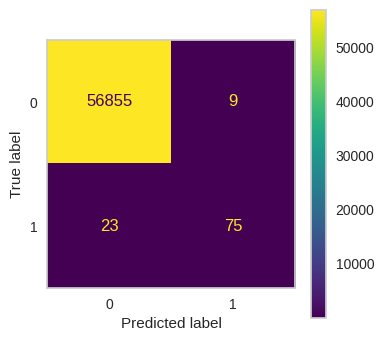




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.99      0.99      0.99       394

    accuracy                           1.00    227845
   macro avg       0.99      1.00      1.00    227845
weighted avg       1.00      1.00      1.00    227845



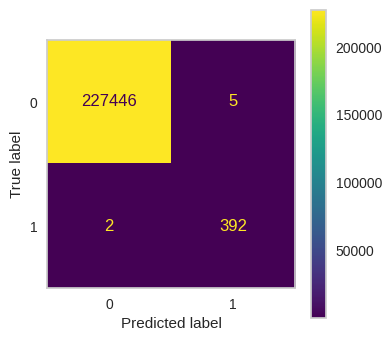

In [11]:
eval_metric(xgb_model, X_train, y_train, X_test, y_test)

## 2.1.2 XGBOOST With Class_Weight

- Unlike the oversampling and under-sampling methods, the balanced weights methods do not modify the minority and majority class ratio. Instead,it penalizes the wrong predictions on the minority class by giving more weight to the loss function.

In [12]:
xgb_cw_model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
xgb_cw_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.82      0.83        98

    accuracy                           1.00     56962
   macro avg       0.93      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



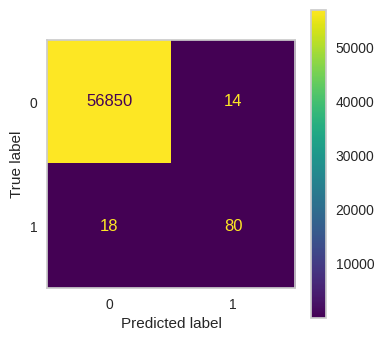




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.99      1.00      0.99       394

    accuracy                           1.00    227845
   macro avg       0.99      1.00      1.00    227845
weighted avg       1.00      1.00      1.00    227845



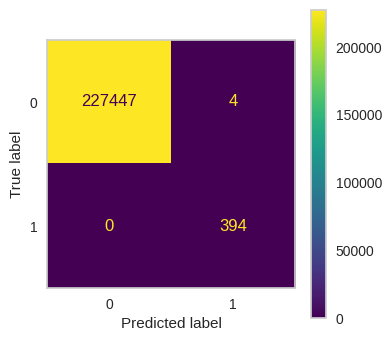

In [13]:
eval_metric(xgb_cw_model, X_train, y_train, X_test, y_test)

### 2.1.3 XGBOOST Model Cross Validation ( StratifiedKFold)¶

In [14]:
skf = StratifiedKFold(n_splits=10,shuffle=True, random_state=0)

In [15]:
model = xgb_cw_model
scores = cross_validate(model, X_train, y_train, scoring = ['precision','recall','f1'], cv = skf, return_train_score=True)
df_scores = pd.DataFrame(scores, index = range(1, 11))
df_scores

,fit_time,score_time,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
1,0.784,0.044,0.821,0.994,0.821,1.000,0.821,0.997
2,0.697,0.043,0.947,0.989,0.900,1.000,0.923,0.994
3,0.664,0.044,0.938,0.992,0.750,1.000,0.833,0.996
4,0.671,0.043,0.946,0.992,0.875,1.000,0.909,0.996
5,0.671,0.045,0.895,0.992,0.850,1.000,0.872,0.996
6,0.666,0.045,0.846,0.994,0.846,1.000,0.846,0.997
7,0.692,0.044,0.903,0.992,0.718,1.000,0.800,0.996
8,0.649,0.045,0.968,0.989,0.769,1.000,0.857,0.994
9,0.679,0.069,0.933,0.989,0.718,1.000,0.812,0.994
10,1.072,0.085,0.968,0.989,0.769,1.000,0.857,0.994


In [17]:
df_scores.mean()[2:]

,0
test_precision,0.916
train_precision,0.991
test_recall,0.802
train_recall,1.000
test_f1,0.853
train_f1,0.996


### 2.1.4 XGBOOST Model With GridsearchCV

In [18]:
model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
param_grid = {"n_estimators":[100,200],
              'max_depth':[2,3,4],
              "learning_rate":[0.08,0.09,0.1],
              "subsample":[0.7,0.8,0.9],
              "colsample_bytree":[0.5,0.6,0.7]
             }
xgb_grid_model = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1, verbose=1)

In [19]:
xgb_grid_model.fit(X_train, y_train)

Fitting 10 folds for each of 162 candidates, totalling 1620 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device='cuda',
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_poli...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.6, 0.7],
                         'learning_rate': [0.08, 0.09, 0.1],
                         'max_depth': [2, 3, 4], 'n_estimators': [100, 200],
                         'subsample': [0.7, 0.8, 0.9]},
             scoring='recall', verbose=1)

In [20]:
xgb_grid_model.best_params_

{'colsample_bytree': 0.6,
 'learning_rate': 0.09,
 'max_depth': 3,
 'n_estimators': 100,
 'subsample': 0.8}

In [22]:
xgb_grid_model.best_score_

0.8422435897435898

In [23]:
xgb_model_best = XGBClassifier(
    random_state=42,
    scale_pos_weight=20,
    max_depth = 3,
    colsample_bytree= 0.6,
    learning_rate= 0.09,
    n_estimators= 100,
    subsample= 0.8,
    device='cuda')  # Enables GPU acceleration

In [24]:
xgb_model_best.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.09, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.68      0.87      0.76        98

    accuracy                           1.00     56962
   macro avg       0.84      0.93      0.88     56962
weighted avg       1.00      1.00      1.00     56962



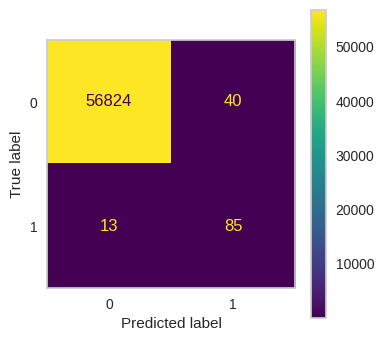




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.75      0.87      0.81       394

    accuracy                           1.00    227845
   macro avg       0.87      0.94      0.90    227845
weighted avg       1.00      1.00      1.00    227845



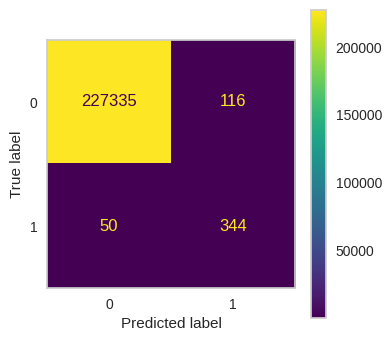

In [25]:
eval_metric(xgb_model_best, X_train, y_train, X_test, y_test)

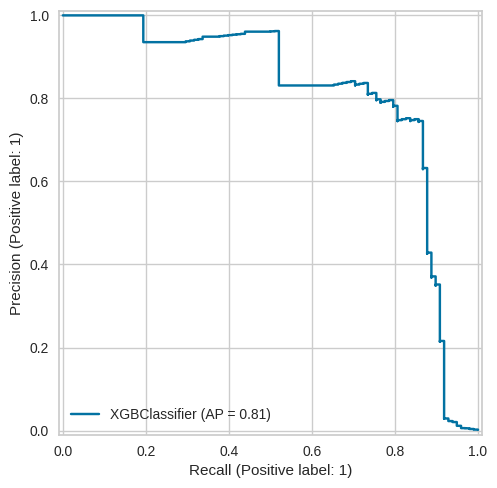

In [26]:
PrecisionRecallDisplay.from_estimator(xgb_model_best, X_test, y_test);

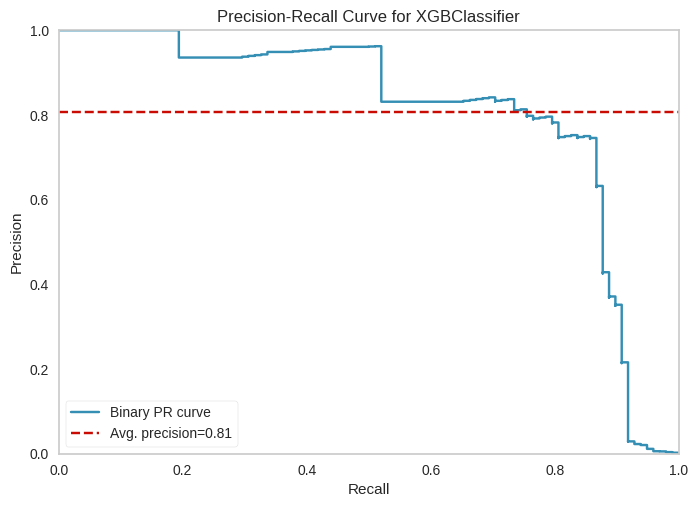

In [27]:
viz = PrecisionRecallCurve( xgb_model_best, per_class=True, cmap="Set1")
viz.fit(X_train, y_train)
viz.score(X_test, y_test)
viz.show();

### Comparison of XGBoost Class-Weighted vs. Optimized GridSearch (Class 1 Metrics)

| Metric (Class 1) | Class-Weighted Model (`xgb_cw_model`) | GridSearch Optimized Model (`xgb_model_best`) | Difference / Trade-off |
| :--- | :---: | :---: | :--- |
| **Precision** | **0.85** | **0.71** | -0.14 (Optimized model produces more False Positives) |
| **Recall** | **0.82** | **0.86** | +0.04 (Optimized model catches more actual frauds) |
| **F1-Score** | **0.83** | **0.77** | -0.06 (Overall balance favors the Class-Weighted model) |



If customer friction is our primary concern, **xgb_cw_model** has significantly fewer false alarms. Lower false positives mean fewer blocked cards and less manual review work for your operations team.
Our goal is to minimize undetected frauds regardless of a few extra false flags so, we will choose **xgb_model_best** model.

In [28]:
y_pred_test = xgb_model_best.predict(X_test)
y_pred_proba = xgb_model_best.predict_proba(X_test)[:, 1]
xgb_model_best_f1 = f1_score(y_test, y_pred_test)
xgb_model_best_recall = recall_score(y_test, y_pred_test)
xgb_model_best_precision = precision_score(y_test, y_pred_test)
xgb_model_best_precision_recall = average_precision_score(y_test, y_pred_proba)

### 3.3.5 Feature Selection With SHAP Method

In [29]:
xgb_model_shap = XGBClassifier(
    random_state=42,
    scale_pos_weight=20,
    max_depth = 3,
    colsample_bytree= 0.6,
    learning_rate= 0.09,
    n_estimators= 100,
    subsample= 0.8,
    device='cuda'
    )
xgb_model_shap.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.09, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [30]:
explainer = shap.TreeExplainer(xgb_model_shap, X_train)
shap_values = explainer.shap_values(X_test)

 99%|===================| 56337/56962 [01:08<00:00]       

#### 3.3.5.1 SHAP Summary Plot

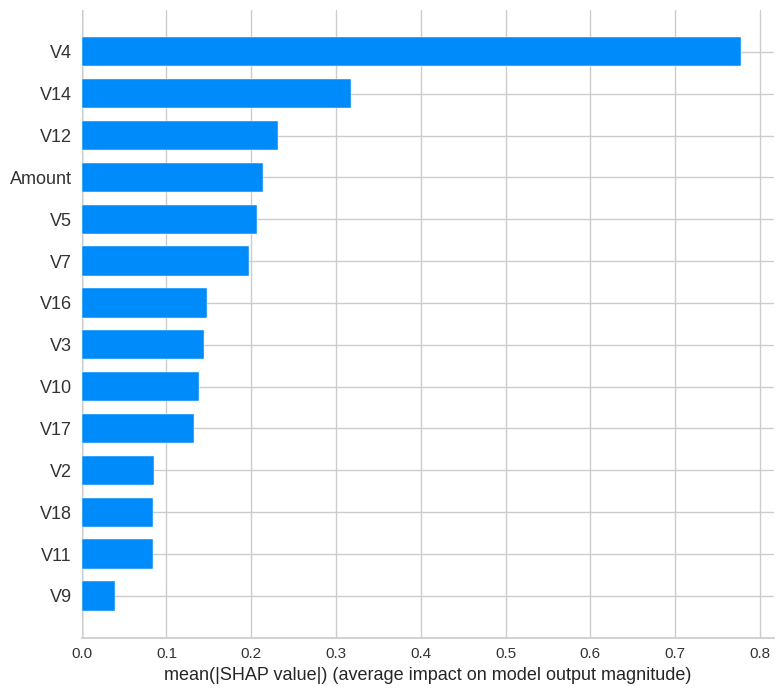

In [31]:
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=X_test.columns)

### 3.3.5.2 Detailed SHAP Beeswarm Summary Plot
Unlike the basic bar chart, the beeswarm plot displays how the value of a feature (from low to high, indicated by color) influences the model's output in the positive or negative direction.

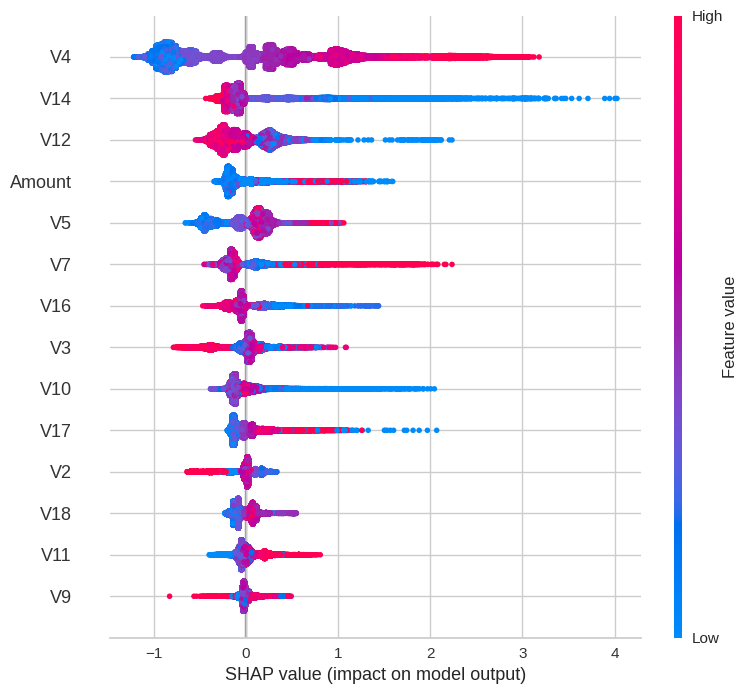

In [32]:
# Standard SHAP summary plot (Beeswarm style)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=X_test.columns)

- On the SHAP beeswarm plot, **the red dots(high values of V4)** are clustered on the right side (positive SHAP values, which **increase the model's prediction of fraud**).
- If you look at** V14** (often the most important feature in this dataset), **the blue dots (low values of V14) are clustered on the right side of the zero line**. Meanwhile, the red dots (high values of V14) are grouped on the left side (**negative SHAP values, which push the model towards predicting normal transactions**).

In [33]:
xgb_f_impact = ['V4', 'V14', 'V12','Amount']

In [34]:
# Select the key features from X_train and X_test directly using xgb_f_impact
X_xgb_train = X_train[xgb_f_impact]
X_xgb_test = X_test[xgb_f_impact]

In [35]:
xgb_model_shap.fit(X_xgb_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.09, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.55      0.86      0.67        98

    accuracy                           1.00     56962
   macro avg       0.77      0.93      0.83     56962
weighted avg       1.00      1.00      1.00     56962



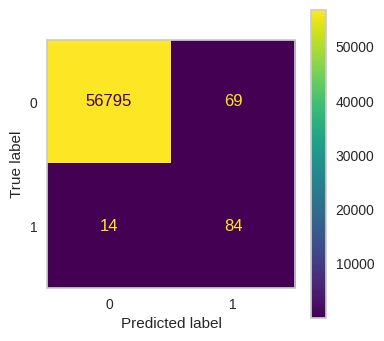




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.61      0.84      0.71       394

    accuracy                           1.00    227845
   macro avg       0.80      0.92      0.85    227845
weighted avg       1.00      1.00      1.00    227845



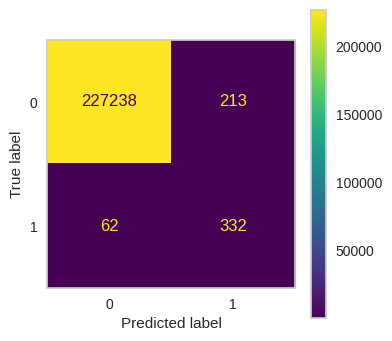

In [36]:
eval_metric(xgb_model_shap, X_xgb_train, y_train, X_xgb_test, y_test)

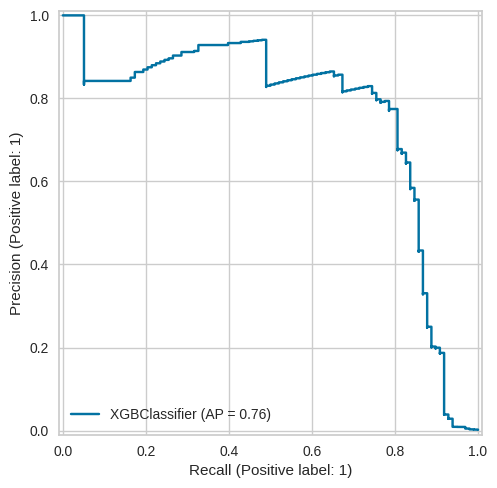

In [37]:
PrecisionRecallDisplay.from_estimator(xgb_model_shap, X_xgb_test, y_test);

In [38]:
y_pred_test = xgb_model_shap.predict(X_xgb_test)
y_pred_proba = xgb_model_shap.predict_proba(X_xgb_test)[:, 1]
xgb_model_shap_f1 = f1_score(y_test, y_pred_test)
xgb_model_shap_recall = recall_score(y_test, y_pred_test)
xgb_model_shap_precision = precision_score(y_test, y_pred_test)
xgb_model_shap_precision_recall = average_precision_score(y_test, y_pred_proba)

### 3.3.6 Applying Resampling Techniques for XGBOOST

#### 3.3.6.1 Random Over Sampling With GridsearchCV

In [39]:
ros = RandomOverSampler()
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

In [43]:
model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
param_grid = {"n_estimators":[100,200],
              "max_depth":[1,2,3],
              "learning_rate":[0.1,0.2,0.3],
              "subsample":[0.4,0.5,0.6],
              "colsample_bytree":[0.4,0.5,0.6]
             }
xgb_grid_model_over = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1, verbose=1)

In [44]:
xgb_grid_model_over.fit(X_train_ros, y_train_ros)

Fitting 10 folds for each of 162 candidates, totalling 1620 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device='cuda',
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_poli...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.4, 0.5, 0.6],
                         'learning_rate': [0.1, 0.2, 0.3],
                         'max_depth': [1, 2, 3], 'n_estimators': [100, 200],
                         'subsample': [0.4, 0.5, 0.6]},
             scoring='recall', verbose=1)

In [45]:
xgb_grid_model_over.best_params_

{'colsample_bytree': 0.4,
 'learning_rate': 0.1,
 'max_depth': 1,
 'n_estimators': 100,
 'subsample': 0.4}

In [ ]:
xgb_grid_model_over.best_score_

1.0

In [49]:
xgb_model_over = XGBClassifier(
    random_state=42,
    max_depth = 1,
    colsample_bytree= 0.4,
    learning_rate= 0.1,
    n_estimators= 100,
    scale_pos_weight=20,
    subsample= 0.4,
    device='cuda' )

In [50]:
xgb_model_over.fit(X_train_ros, y_train_ros)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=1,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      0.68      0.81     56864
           1       0.01      0.97      0.01        98

    accuracy                           0.68     56962
   macro avg       0.50      0.83      0.41     56962
weighted avg       1.00      0.68      0.81     56962



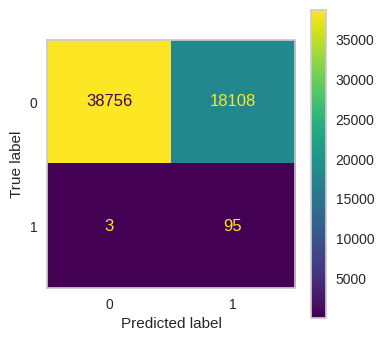




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      0.68      0.81    227451
           1       0.76      1.00      0.86    227451

    accuracy                           0.84    454902
   macro avg       0.88      0.84      0.84    454902
weighted avg       0.88      0.84      0.84    454902



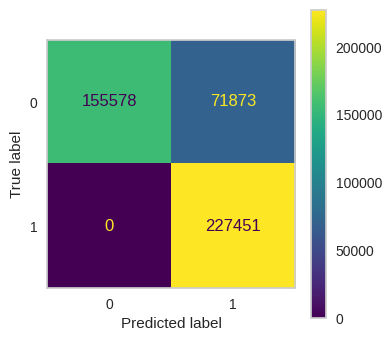

In [51]:
eval_metric(xgb_model_over, X_train_ros, y_train_ros, X_test, y_test)

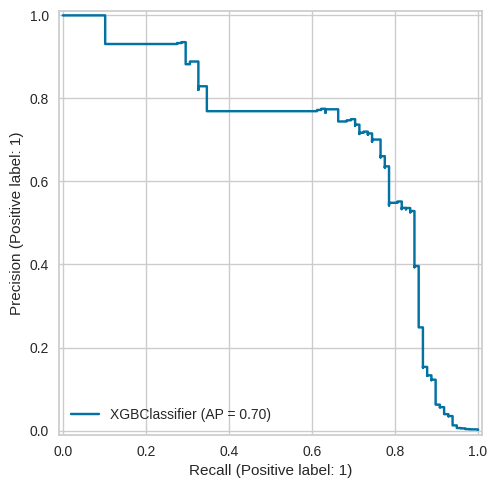

In [52]:
PrecisionRecallDisplay.from_estimator(xgb_model_over, X_test, y_test);

In [53]:
y_pred_test = xgb_model_over.predict(X_test)
y_pred_proba = xgb_model_over.predict_proba(X_test)[:, 1]
xgb_model_over_f1 = f1_score(y_test, y_pred_test)
xgb_model_over_recall = recall_score(y_test, y_pred_test)
xgb_model_over_precision = precision_score(y_test, y_pred_test)
xgb_model_over_precision_recall = average_precision_score(y_test, y_pred_proba)

#### 3.3.6.2 SMOTE With XGBOOST Method

In [54]:
smt = SMOTE()

In [55]:
X_train_smt, y_train_smt = smt.fit_resample(X_train, y_train)

In [56]:
model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
param_grid = {"n_estimators":[100,200],
              'max_depth':[4,5,6],
              "learning_rate":[0.5,0.7,0.9],
              "subsample":[0.3,0.5,0.7],
              "colsample_bytree":[0.3,0.5,0.7]
             }
xgb_grid_model_smt = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1, verbose=1)

In [57]:
xgb_grid_model_smt.fit(X_train_smt, y_train_smt)

Fitting 10 folds for each of 162 candidates, totalling 1620 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device='cuda',
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_poli...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.3, 0.5, 0.7],
                         'learning_rate': [0.5, 0.7, 0.9],
                         'max_depth': [4, 5, 6], 'n_estimators': [100, 200],
                         'subsample': [0.3, 0.5, 0.7]},
             scoring='recall', verbose=1)

In [58]:
xgb_grid_model_smt.best_params_

{'colsample_bytree': 0.3,
 'learning_rate': 0.5,
 'max_depth': 4,
 'n_estimators': 100,
 'subsample': 0.3}

In [59]:
xgb_model_smt = XGBClassifier(
    random_state=42,
    max_depth = 4,
    colsample_bytree= 0.3,
    learning_rate= 0.5,
    n_estimators= 100,
    subsample= 0.3,
    device='cuda'
    )

In [60]:
xgb_model_smt.fit(X_train_smt, y_train_smt)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.3, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.5, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.26      0.88      0.40        98

    accuracy                           1.00     56962
   macro avg       0.63      0.94      0.70     56962
weighted avg       1.00      1.00      1.00     56962



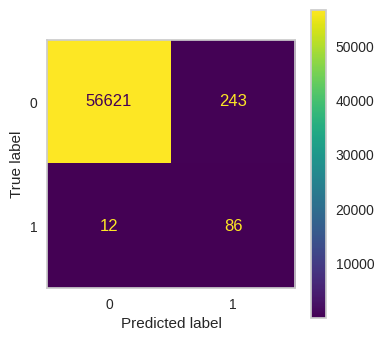




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       1.00      1.00      1.00    227451

    accuracy                           1.00    454902
   macro avg       1.00      1.00      1.00    454902
weighted avg       1.00      1.00      1.00    454902



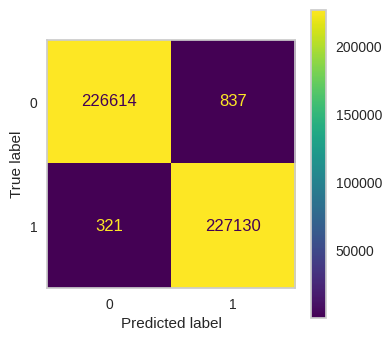

In [61]:
eval_metric(xgb_model_smt, X_train_smt, y_train_smt, X_test, y_test)

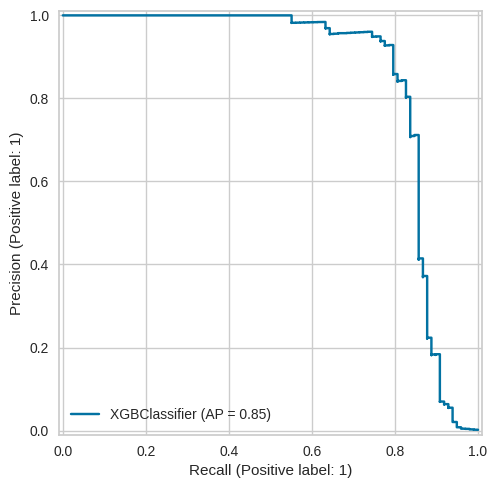

In [62]:
PrecisionRecallDisplay.from_estimator(xgb_model_smt, X_test, y_test);

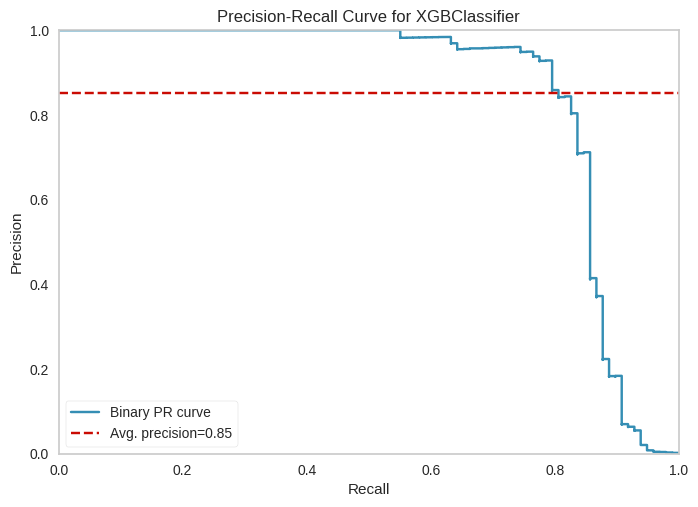

In [63]:
viz = PrecisionRecallCurve( xgb_model_smt, per_class=True, cmap="Set1")
viz.fit(X_train, y_train)
viz.score(X_test, y_test)
viz.show();

#### 3.3.6.3 SMOTE + ENN With XGBOOST Method

In [64]:
from imblearn.combine import SMOTEENN
smenn = SMOTEENN()

In [65]:
X_train_smenn, y_train_smenn = smenn.fit_resample(X_train, y_train)

In [66]:
model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
param_grid = {"n_estimators":[100,200],
              'max_depth':[4,5,6],
              "learning_rate":[0.6, 0.7, 0.8],
              "subsample":[0.5,0.6,0.7],
              "colsample_bytree":[0.5,0.6,0.7]
             }
xgb_grid_model_smenn = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1, verbose=1)

In [67]:
xgb_grid_model_smenn.fit(X_train_smenn, y_train_smenn)

Fitting 10 folds for each of 162 candidates, totalling 1620 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device='cuda',
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_poli...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.6, 0.7],
                         'learning_rate': [0.6, 0.7, 0.8],
                         'max_depth': [4, 5, 6], 'n_estimators': [100, 200],
                         'subsample': [0.5, 0.6, 0.7]},
             scoring='recall', verbose=1)

In [68]:
xgb_grid_model_smenn.best_params_

{'colsample_bytree': 0.5,
 'learning_rate': 0.6,
 'max_depth': 4,
 'n_estimators': 100,
 'subsample': 0.5}

In [69]:
xgb_model_smenn = XGBClassifier(
    random_state=42,
    max_depth = 4,
    colsample_bytree= 0.5,
    learning_rate= 0.6,
    n_estimators= 100,
    subsample= 0.5,
    device='cuda'
    )

In [70]:
xgb_model_smenn.fit(X_train_smenn, y_train_smenn)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.6, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.38      0.89      0.53        98

    accuracy                           1.00     56962
   macro avg       0.69      0.94      0.76     56962
weighted avg       1.00      1.00      1.00     56962



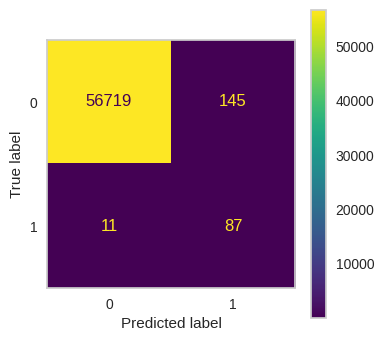




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    226928
           1       1.00      1.00      1.00    227450

    accuracy                           1.00    454378
   macro avg       1.00      1.00      1.00    454378
weighted avg       1.00      1.00      1.00    454378



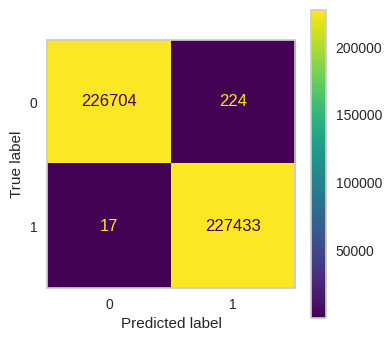

In [71]:
eval_metric(xgb_model_smenn, X_train_smenn, y_train_smenn, X_test, y_test)

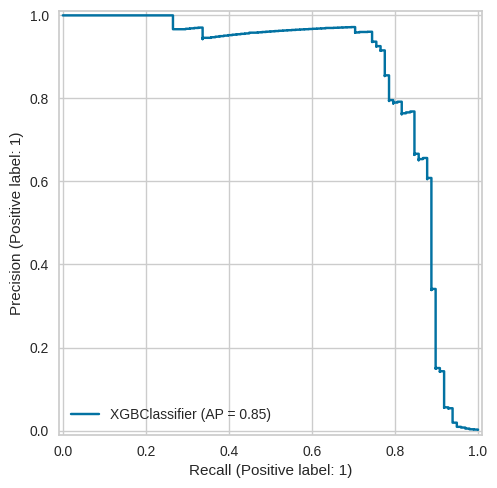

In [72]:
PrecisionRecallDisplay.from_estimator(xgb_model_smenn, X_test, y_test);

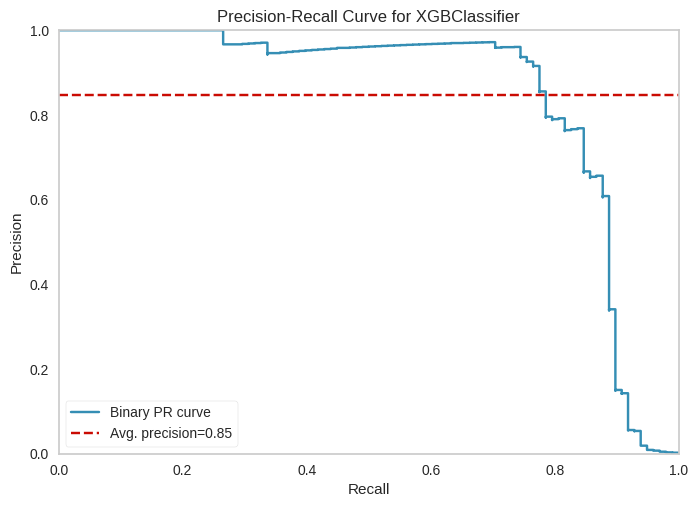

In [73]:
viz = PrecisionRecallCurve( xgb_model_smenn, per_class=True, cmap="Set1")
viz.fit(X_train, y_train)
viz.score(X_test, y_test)
viz.show();

#### 3.3.6.4 SMOTE + Random Under Sampling With XGBOOST Method

In [74]:
over = SMOTE(sampling_strategy={1: 5000}, k_neighbors=7, random_state=42)
under = RandomUnderSampler(sampling_strategy={0: 100000}, random_state=42)

In [75]:
X_resampled, y_resampled = over.fit_resample(X_train, y_train)

In [76]:
X_resampled, y_resampled = under.fit_resample(X_resampled, y_resampled)

In [77]:
param_grid = {"n_estimators":[100,200],
              'max_depth':[4,5,6],
              "learning_rate":[0.6, 0.7, 0.8],
              "subsample":[0.5,0.6,0.7],
              "colsample_bytree":[0.5,0.6,0.7]
             }

In [78]:
model = XGBClassifier(random_state=42, scale_pos_weight=20, device='cuda')
param_grid = {"n_estimators":[100,200],
              'max_depth':[2,3,4,5],
              "learning_rate":[0.1, 0.2, 0.3],
              "subsample":[0.7,0.8,0.9],
              "colsample_bytree":[0.7,0.8,0.9]
             }
xgb_grid_model_su = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1, verbose=1)

In [79]:
xgb_grid_model_su.fit(X_resampled, y_resampled)

Fitting 10 folds for each of 216 candidates, totalling 2160 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device='cuda',
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_poli...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.7, 0.8, 0.9],
                         'learning_rate': [0.1, 0.2, 0.3],
                         'max_depth': [2, 3, 4, 5], 'n_estimators': [100, 200],
                         'subsample': [0.7, 0.8, 0.9]},
             scoring='recall', verbose=1)

In [80]:
xgb_grid_model_su.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.2,
 'max_depth': 4,
 'n_estimators': 200,
 'subsample': 0.8}

In [81]:
xgb_model_su = XGBClassifier(random_state=42,
                             max_depth = 4,
                             colsample_bytree= 0.8,
                             learning_rate= 0.2,
                             n_estimators= 200,
                             subsample= 0.8,
                             device='cuda')

In [82]:
xgb_model_su.fit(X_resampled, y_resampled)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.70      0.85      0.76        98

    accuracy                           1.00     56962
   macro avg       0.85      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962



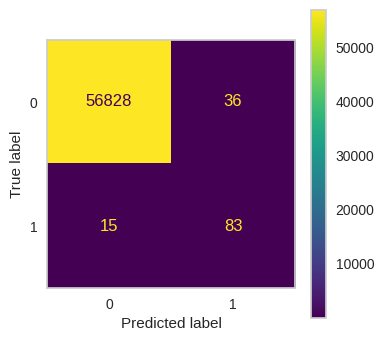




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    100000
           1       1.00      0.99      1.00      5000

    accuracy                           1.00    105000
   macro avg       1.00      1.00      1.00    105000
weighted avg       1.00      1.00      1.00    105000



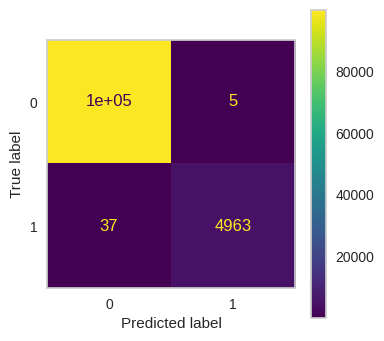

In [83]:
eval_metric(xgb_model_su, X_resampled, y_resampled, X_test, y_test)

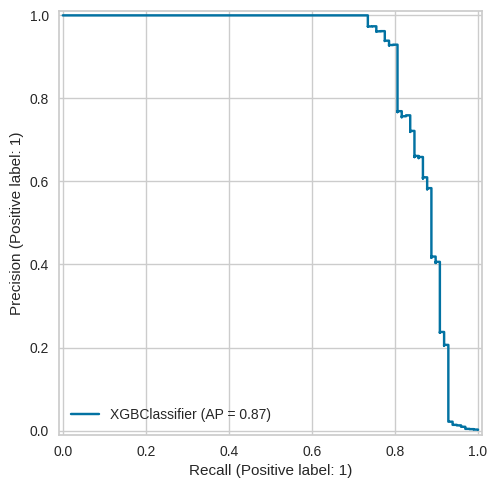

In [84]:
PrecisionRecallDisplay.from_estimator(xgb_model_su, X_test, y_test);

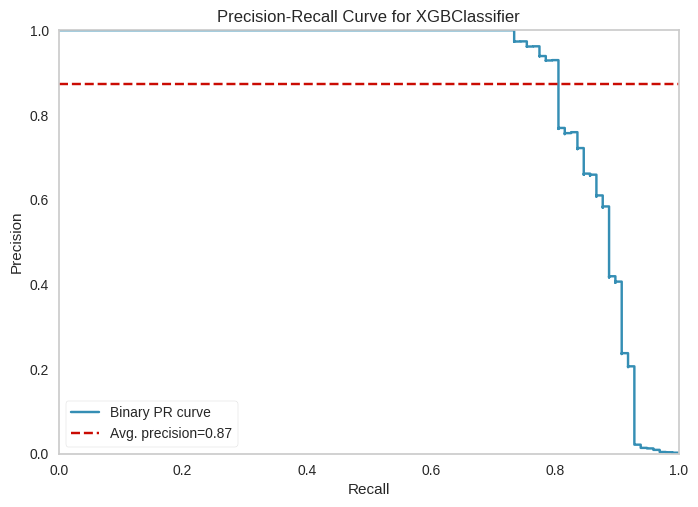

In [85]:
viz = PrecisionRecallCurve( xgb_model_su, per_class=True, cmap="Set1")
viz.fit(X_train, y_train)
viz.score(X_test, y_test)
viz.show();

- When we analyze the results, xgb_model_su and xgb_model_best models are best options. **Both models have the same result for recall**.  **xgb_model_best has better precision (0.706) and F1 (0.774) results compared to xgb_model_su**. On the other hand, **xgb_model_su has a superior PR-AUC (0.863) compared to the GridSearch Best model**.
- **The Core Difference: Single-Point Metrics vs. Curve-Area Metrics**:
     - **Precision**, **Recall**, and **F1-Score** are Single-Point Metrics. They are calculated at a single, fixed decision threshold (by default, 0.5). When you look at the best model having a 0.706 Precision and 0.774 F1-score, you are evaluating its behavior only at that specific 0.5 threshold.
     - **PR-AUC (Precision-Recall Area Under Curve)** is a Global Metric. It calculates the area under the entire curve across all possible classification thresholds (from 0.0 to 1.0).
  
  If we are **not planing to change the treshold, xgb_model_best we use**. If we **plan to optimize decision thresholds** operationally, this time **xgb_model_su is the best** option.

  Sophisticated banks don't just use one threshold; they dynamic tune them based on real-time metadata.

In [86]:
y_pred_test = xgb_model_su.predict(X_test)
y_pred_proba = xgb_model_su.predict_proba(X_test)[:, 1]
xgb_model_su_f1 = f1_score(y_test, y_pred_test)
xgb_model_su_recall = recall_score(y_test, y_pred_test)
xgb_model_su_precision = precision_score(y_test, y_pred_test)
xgb_model_su_precision_recall = average_precision_score(y_test, y_pred_proba)

### 3.3.7 Model Evaluation Check

In [87]:
import numpy as np
# Hotfix for NumPy 2.0 compatibility with older libraries like deepchecks
if not hasattr(np, 'Inf'):
    np.Inf = np.inf

from deepchecks.tabular.suites import model_evaluation

In [88]:
from deepchecks.tabular import Dataset

# Instantiate the Deepchecks Datasets using the original full-feature splits for xgb_model_su
train_ds = Dataset(X_train, label=y_train, cat_features=[])
test_ds = Dataset(X_test, label=y_test, cat_features=[])

In [89]:
evaluation_suite = model_evaluation()
suite_result = evaluation_suite.run(train_ds, test_ds, xgb_model_su)
suite_result.show()

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Model Evaluation Suite

**Why did it happen with your model?**

This degradation is a natural byproduct of using SMOTE + Random Under-sampling (RUS) (xgb_model_su) to counter highly imbalanced data:

 1. **Resampled Training Set:** Your training set was augmented with synthetic fraud samples (X_resampled), boosting Class 1's share to roughly 4.7% (5,000 fraud vs. 100,000 non-fraud). Because of this enriched representation, the model achieves very high Precision on the training dataset.
Realistic Imbalanced Test Set: Your test set (X_test) maintains the original, real-world distribution where Fraud is extremely rare (only 0.172% of the entire dataset). When predicting on this imbalanced test set, the model naturally encounters more False Positives relative to the tiny number of actual True Positives, dropping the test Precision.
 2. **Should you be worried?**
Not necessarily. In extremely imbalanced scenarios (like fraud detection), some Precision degradation on the test set is expected in order to maintain a strong Recall (catching 81% to 85% of actual frauds).
However, a degradation of 17.96% confirms that the model has slight overfitting to the resampled training distribution.
 3. **How to mitigate this degradation:**
If you want to bring the Train-Test gap closer together (and pass this test):

     - Slightly lower max_depth (e.g., from 4 down to 3) or decrease the learning_rate on your XGBClassifier to make the tree patterns more generalized.
     - Increase subsample or colsample_bytree regularization to prevent individual trees from over-memorizing synthetic SMOTE samples.

# 4. Model Comparison

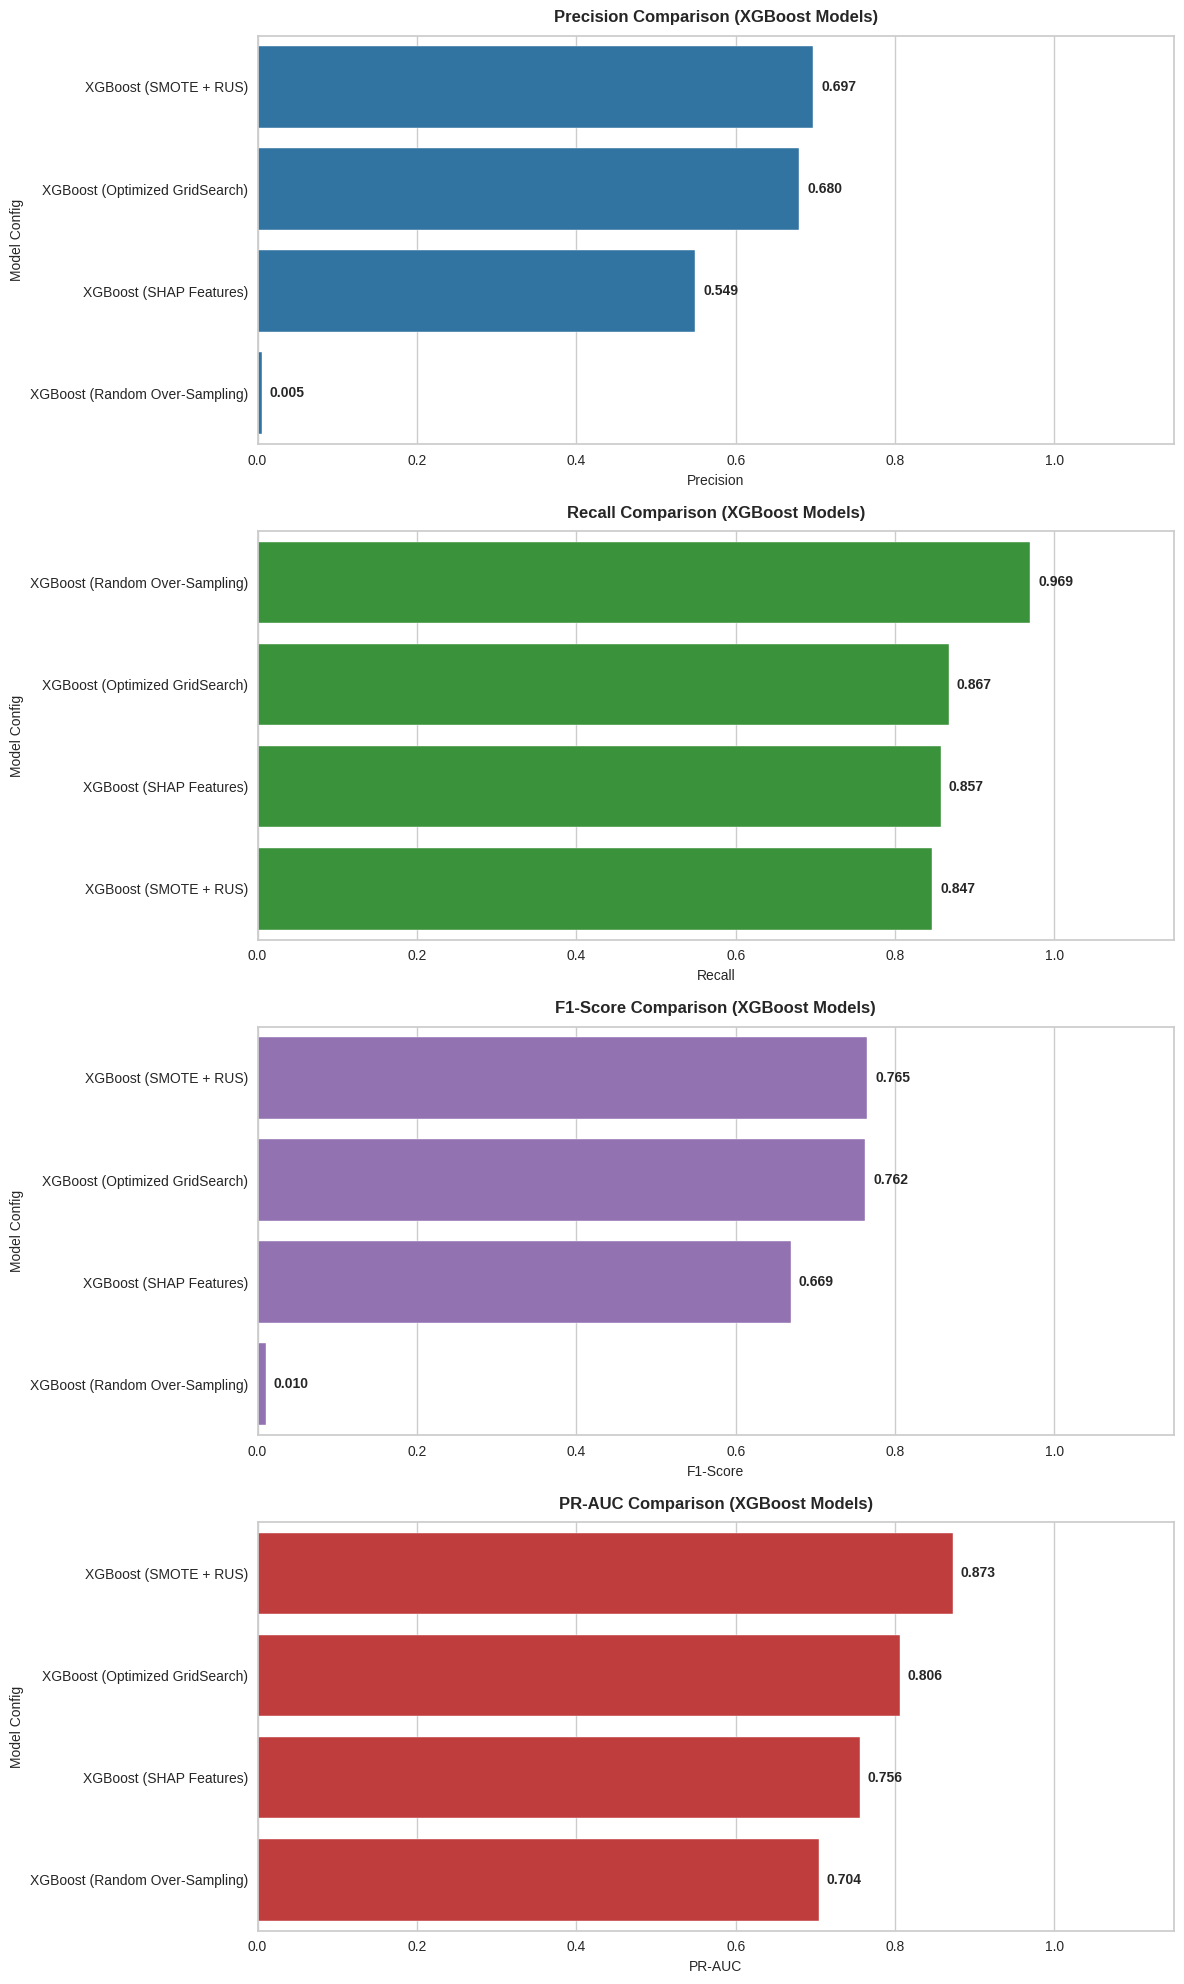

In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dynamic data structure using active metrics from the workspace variables
xgb_comparison_data = {
    "Model": [
        "XGBoost (Optimized GridSearch)",
        "XGBoost (SHAP Features)",
        "XGBoost (Random Over-Sampling)",
        "XGBoost (SMOTE + RUS)"
    ],
    "Precision": [
        xgb_model_best_precision,
        xgb_model_shap_precision,
        xgb_model_over_precision,
        xgb_model_su_precision
    ],
    "Recall": [
        xgb_model_best_recall,
        xgb_model_shap_recall,
        xgb_model_over_recall,
        xgb_model_su_recall
    ],
    "F1-Score": [
        xgb_model_best_f1,
        xgb_model_shap_f1,
        xgb_model_over_f1,
        xgb_model_su_f1
    ],
    "PR-AUC": [
        xgb_model_best_precision_recall,
        xgb_model_shap_precision_recall,
        xgb_model_over_precision_recall,
        xgb_model_su_precision_recall
    ]
}

xgb_compare_df = pd.DataFrame(xgb_comparison_data)

def annotate_horizontal_bars(ax):
    """Helper to label horizontal bars with exact scores"""
    for p in ax.patches:
        width = p.get_width()
        ax.text(width + 0.01,
                p.get_y() + p.get_height() / 2,
                f"{width:.3f}",
                va='center',
                ha='left',
                fontsize=10,
                fontweight='bold')

# Plot configuration setup with a grid layout
fig, axes = plt.subplots(4, 1, figsize=(12, 20))
metrics = ["Precision", "Recall", "F1-Score", "PR-AUC"]
colors = ["#1f77b4", "#2ca02c", "#9467bd", "#d62728"]

for i, (metric, color) in enumerate(zip(metrics, colors)):
    sorted_df = xgb_compare_df.sort_values(by=metric, ascending=False)
    # Set height parameter to 0.8 to make the horizontal bars thicker as requested
    sns.barplot(x=metric, y="Model", data=sorted_df, ax=axes[i], color=color, height=0.8)
    axes[i].set_title(f"{metric} Comparison (XGBoost Models)", fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlim(0, 1.15)
    axes[i].set_xlabel(metric, fontsize=10)
    axes[i].set_ylabel("Model Config", fontsize=10)
    annotate_horizontal_bars(axes[i])

plt.tight_layout()
plt.show()

In [94]:
compare = xgb_compare_df.sort_values(by="PR-AUC", ascending=False)
compare

,Model,Precision,Recall,F1-Score,PR-AUC
3,XGBoost (SMOTE + RUS),0.697,0.847,0.765,0.873
0,XGBoost (Optimized GridSearch),0.680,0.867,0.762,0.806
1,XGBoost (SHAP Features),0.549,0.857,0.669,0.756
2,XGBoost (Random Over-Sampling),0.005,0.969,0.010,0.704


# 5. Model Saving and Deployment

## 5.1 Model Saving

### 5.1.1 With Joblib Method

- Pickle is a module in Python that allows you to serialize and deserialize machine learning models. You typically fit the model to your data using the fit method before saving it, and then you can save the trained model using pickle for later use. Joblib is more efficient than pickle when working with large machine learning models or large numpy arrays.
- To save the ML model using Pickle all we need to do is pass the model object into the dump() function of Pickle. This will serialize the object and convert it into a “byte stream” that we can save as a file called model.pkl.

#### 5.1.1.3 Joblib for XGBOOST

In [95]:
xgb_model_best = xgb_model_su
joblib.dump(xgb_model_best, '/content/drive/My Drive/fraud_xgb_model.joblib')

['/content/drive/My Drive/fraud_xgb_model.joblib']

In [96]:
xgb_model_best = joblib.load('/content/drive/My Drive/fraud_xgb_model.joblib')

In [ ]:
# # Joblib method for other notebooks
# from sklearn.externals import joblib
# from joblib import dump
# with open('XGBoost_joblib', 'wb') as f:
#     joblib.dump(xgb_model_best, f, protocol=pickle.HIGHEST_PROTOCOL)

# #Using protocol=pickle.HIGHEST_PROTOCOL is recommended to reduce memory usage and make it faster to store and
# #load any large NumPy array stored as a fitted attribute in the model in Python 3.8 and later.

In [ ]:
# from joblib import load
# with open('XGBoost.joblib', 'rb') as f:
#     xgb_model_best = joblib.load(f)


To allow your friend or customer to use **your final model**(the pickled XGBoost model), you need to provide them with two things:

**1. The Pickled Model File (XGBoost_joblib):** Share this file with them through a suitable method (email, file sharing platform, etc.).

**2. Python Code to Load and Use the Model:** Give them a Python script or instructions containing the following:
 1. importing necessary libraries or library objects/estimators/etc.
 2. Load the model
   with open('XGBoost_joblib', 'rb') as file:
    loaded_model = joblib.load(file)
 3.  Make predictions using the loaded model
predictions = loaded_model.predict(their_preprocessed_data)
